# Ages of Olympic medalists in two periods

Were medalists in the early Olympic Games older than later ones? This notebook compares the ages of medalists in two periods, 1890–1930 (G1) and 1950–1990 (G2), with descriptive statistics, a frequency table and bar charts. It is the analysis the course first did in Excel and then in pandas, so each step shows the spreadsheet formula next to the code.

**Data.** Olympic medal results from 1896 to 2016, one row per medal won by one athlete. See [`data/README.md`](../data/README.md).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/olympic-medalists.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39783 entries, 0 to 39782
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Age     39051 non-null  float64
 1   Height  31072 non-null  float64
 2   Weight  30456 non-null  float64
 3   Year    39783 non-null  int64  
 4   Medal   39783 non-null  object 
dtypes: float64(3), int64(1), object(1)
memory usage: 1.5+ MB


Keep the three columns the question needs, and drop the medals with no recorded age.

In [2]:
df2 = df[["Age", "Year", "Medal"]].dropna()
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39051 entries, 0 to 39782
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Age     39051 non-null  float64
 1   Year    39051 non-null  int64  
 2   Medal   39051 non-null  object 
dtypes: float64(1), int64(1), object(1)
memory usage: 1.2+ MB


## Split into the two periods

Each period is a year range, both ends included.

In [3]:
a, b = 1890, 1930   # G1
c, d = 1950, 1990   # G2

G1 = df2[(df2["Year"] >= a) & (df2["Year"] <= b)]["Age"]
G2 = df2[(df2["Year"] >= c) & (df2["Year"] <= d)]["Age"]
len(G1), len(G2)

(5876, 13672)

## Descriptive statistics

In the spreadsheet, each statistic was one formula over the column of ages:

| Statistic | Excel | pandas |
|---|---|---|
| Count | `=COUNT(B3:B6558)` | `s.count()` |
| Mean | `=AVERAGE(B3:B6558)` | `s.mean()` |
| Median | `=MEDIAN(B3:B6558)` | `s.median()` |
| Mode | `=MODE(B3:B6558)` | `s.mode()` |
| Standard deviation | `=STDEV(B3:B6558)` | `s.std()` |
| Maximum, minimum | `=MAX(...)`, `=MIN(...)` | `s.max()`, `s.min()` |
| Range | `=F7-F8` | `s.max() - s.min()` |

In [4]:
def summary(s):
    """The statistics the course asked for, in the same order as the spreadsheet."""
    return pd.Series({
        "count": s.count(),
        "mean": s.mean(),
        "median": s.median(),
        "mode": s.mode().iloc[0] if s.duplicated().any() else float("nan"),
        "std": s.std(),
        "max": s.max(),
        "min": s.min(),
        "range": s.max() - s.min(),
    })

stats = pd.DataFrame({f"G1 {a}-{b}": summary(G1), f"G2 {c}-{d}": summary(G2)})
stats.round(2)

,G1 1890-1930,G2 1950-1990
count,5876.0,13672.00
mean,27.8,24.89
median,26.0,24.00
mode,24.0,23.00
std,8.2,5.23
max,72.0,66.00
min,10.0,13.00
range,62.0,53.00


Medalists in G1 were about three years older on average (27.8 against 24.9) and much more spread out: a standard deviation of 8.2 years against 5.2, and ages from 10 to 72 against 13 to 66. In both periods the mean is above the median, because a tail of older medalists pulls it up.

`describe()` gives most of these numbers at once, plus the quartiles.

In [5]:
pd.concat([G1.describe().rename("G1"), G2.describe().rename("G2")], axis=1).round(2)

,G1,G2
count,5876.0,13672.00
mean,27.8,24.89
std,8.2,5.23
min,10.0,13.00
25%,22.0,21.00
50%,26.0,24.00
75%,32.0,27.00
max,72.0,66.00


## Frequency table

The ages go into 5-year classes from 10 to 75. Each class includes its lower limit and excludes the upper one, like the spreadsheet formula `=COUNTIFS(B:B,">="&J2,B:B,"<"&K2)`.

In [6]:
intervals = pd.interval_range(start=10, end=75, freq=5, closed="left")

FG1 = pd.cut(G1, bins=intervals).value_counts(sort=False)
FG2 = pd.cut(G2, bins=intervals).value_counts(sort=False)
table = pd.concat([FG1.rename("G1"), FG2.rename("G2")], axis=1)
table

,G1,G2
Age,,
"[10, 15)",24,49
"[15, 20)",503,1437
"[20, 25)",1991,5695
"[25, 30)",1450,4479
"[30, 35)",891,1412
"[35, 40)",444,355
"[40, 45)",302,142
"[45, 50)",134,62
"[50, 55)",72,27


## Histograms in one chart

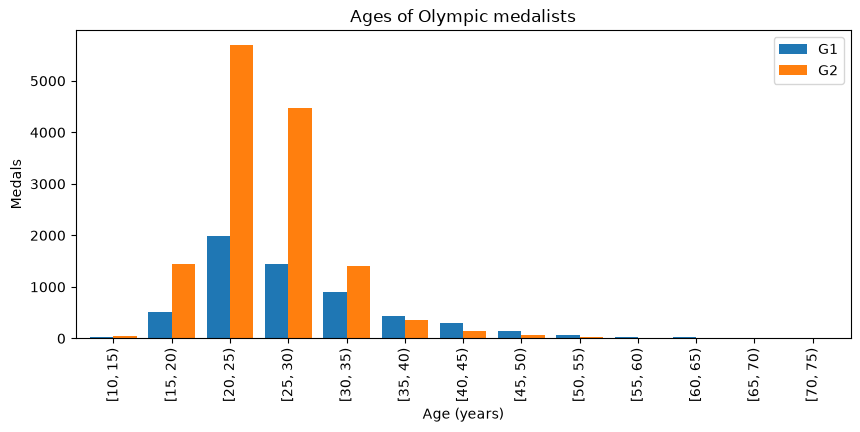

In [7]:
ax = table.plot(kind="bar", figsize=(10, 4), width=0.8)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Medals")
ax.set_title("Ages of Olympic medalists")
plt.show()

G2 has more than twice as many medals as G1, so compare the shapes rather than the heights. G2 is concentrated between 20 and 30, while G1 has a visible share of medalists in their 40s, 50s and 60s.

## Notes

- Each row is a medal, not an athlete. An athlete who won three medals counts three times, and a team event gives one row to every member of the team.
- There were no Games between 1890 and 1895, so G1 starts in practice with Athens 1896.
- Excel's `STDEV` and pandas' `std()` both compute the sample standard deviation, dividing by n − 1. NumPy's `np.std` divides by n unless you pass `ddof=1`.
- `mode()` returns every value that ties for most frequent; `summary` keeps the smallest, while Excel's `MODE` keeps the first one it finds in the column.